##Problem 1

Print handful of images as function of the two position coordinates ($x$ and $y$)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


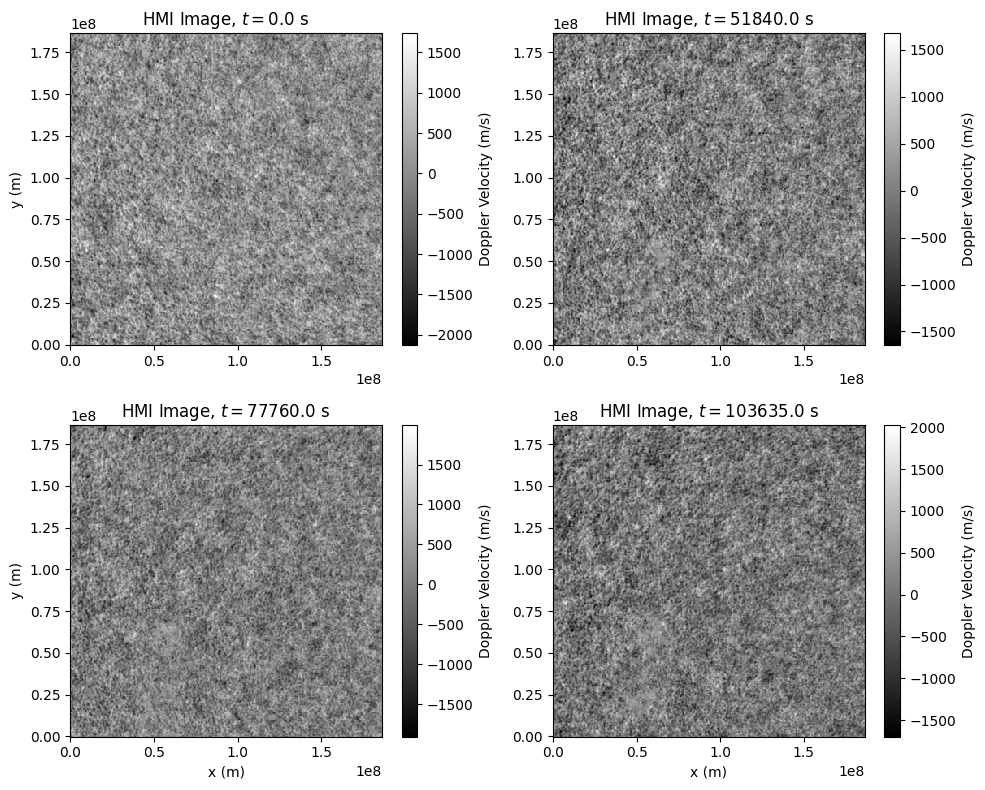

In [31]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive
from astropy.io import fits

#First, import the FITS file (it's big so it would be an utter pain in the ass to import everytime)
drive.mount('/content/drive')

# Make a timeseries of the HMI data
hdul = fits.open('/content/drive/MyDrive/hmi.rdVtrack_fd15.2121.225.225.0.-22.5.-00.0.V.fits')

header = hdul[0].header
data = hdul[0].data

r_sun = 696340000

#Get mapscale and cadence
mapscale = header['MAPSCALE']
cadence = header['CADENCE']

#Define function to convert resolution into meters
def convert_to_meters(x):
  conversion_factor = 2 * np.pi * r_sun / 360
  return mapscale * x * conversion_factor

t, x, y = data.shape
x = np.arange(0, x)
y = np.arange(0, y)
t = np.arange(0, t)

#Now print images as function of x and y, making sure to convert into meters
x_coords = convert_to_meters(x)
y_coords = convert_to_meters(y)

# Create a 2x2 grid of subplots
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 8))

#Plot image on axs[0,0]
#NOTE: take transpose because rows = y, columns = x   (what pcolormesh expects)
#currently, because x=longitude and y=latitude, it is swapped
im = axs[0,0].pcolormesh(x_coords, y_coords, data[0].T, shading='auto', cmap='gray')
fig.colorbar(im, ax=axs[0,0], label='Doppler Velocity (m/s)')
axs[0,0].set_ylabel('y (m)')
axs[0,0].set_title(f'HMI Image, $t={t[0]*cadence}$ s')

#Plot image on axs[0,1]
im = axs[0,1].pcolormesh(x_coords, y_coords, data[int(len(t)*0.5)].T, shading='auto', cmap='gray')
fig.colorbar(im, ax=axs[0,1], label='Doppler Velocity (m/s)')
axs[0,1].set_title(f'HMI Image, $t={t[int(len(t)*0.5)]*cadence}$ s')

#Plot image on axs[1,0]
im = axs[1,0].pcolormesh(x_coords, y_coords, data[int(len(t)*0.75)].T, shading='auto', cmap='gray')
fig.colorbar(im, ax=axs[1,0], label='Doppler Velocity (m/s)')
axs[1,0].set_ylabel('y (m)')
axs[1,0].set_xlabel('x (m)')
axs[1,0].set_title(f'HMI Image, $t={t[int(len(t)*0.75)]*cadence}$ s')

#Plot image on axs[1,1]
im = axs[1,1].pcolormesh(x_coords, y_coords, data[int(len(t)-1)].T, shading='auto', cmap='gray')
fig.colorbar(im, ax=axs[1,1], label='Doppler Velocity (m/s)')
axs[1,1].set_xlabel('x (m)')
axs[1,1].set_title(f'HMI Image, $t={t[int(len(t)-1)]*cadence}$ s')

plt.tight_layout()
plt.show()

Line plots of the Doppler velocity signal as a function of $x$ or $y$

RMS of (all) images: 399.25427


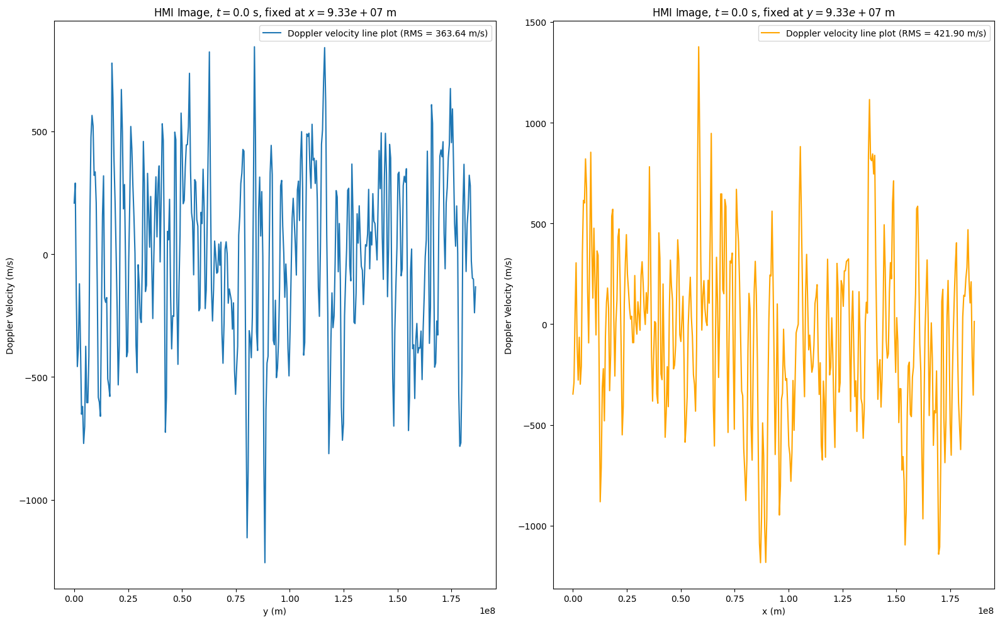

In [32]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive
from astropy.io import fits

# Create a 1x2 grid of subplots
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 10))

#Make function for calculating RMS
def calculate_rms(data):
  return np.sqrt(np.mean(data**2))

#For top two, we fix x to be constant and the bottom two for y to be constant (using the t=0 s image)
# We will select x to be at half and the same for y

# Calculate RMS values for the profiles
rms_y = calculate_rms(data[0, int(len(x)*0.5), :])
rms_x = calculate_rms(data[0, :, int(len(y)*0.5)])
rms = calculate_rms(data[0, :, :])
print("RMS of (all) images:", rms)

#Plot image on axs[0]
axs[0].plot(y_coords, data[0, int(len(x)*0.5), :], label='Doppler velocity line plot (RMS = {:.2f} m/s)'.format(rms_y))
axs[0].set_xlabel('y (m)')
axs[0].set_ylabel('Doppler Velocity (m/s)')
axs[0].set_title(f'HMI Image, $t={t[0]*cadence}$ s, fixed at $x={x_coords[int(len(x)*0.5)]:.2e}$ m')
axs[0].legend()

#Plot image on axs[1]
axs[1].plot(x_coords, data[0, :, int(len(y)*0.5)].T, label='Doppler velocity line plot (RMS = {:.2f} m/s)'.format(rms_x), color='orange')
axs[1].set_xlabel('x (m)')
axs[1].set_ylabel('Doppler Velocity (m/s)')
axs[1].set_title(f'HMI Image, $t={t[0]*cadence}$ s, fixed at $y={y_coords[int(len(y)*0.5)]:.2e}$ m')
axs[1].legend()

plt.tight_layout()
plt.show()

##Problem 2

3D FFT of the data

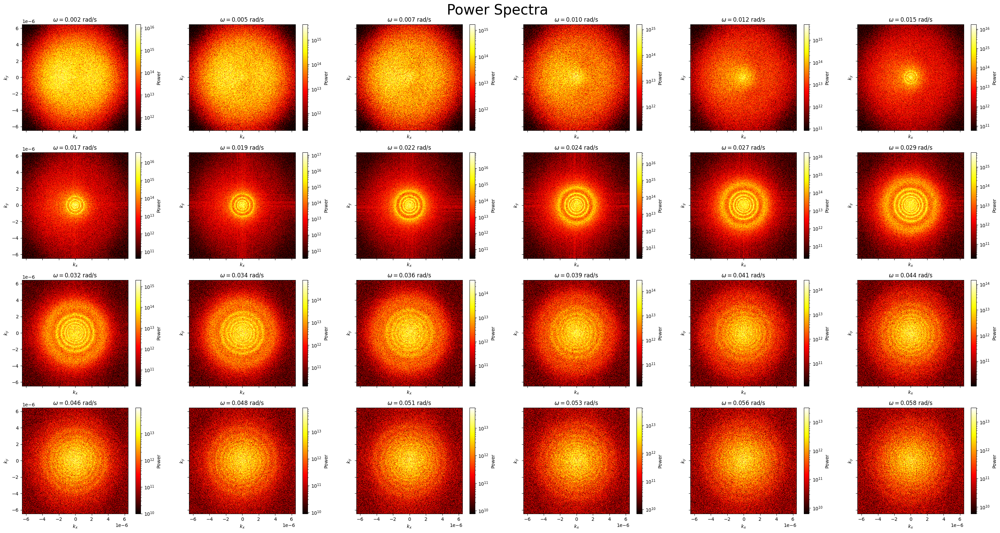

In [21]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
from google.colab import drive
from astropy.io import fits
import scipy.fft as sfft

#Resource used for the 3D FFT: https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.fftn.html$0
# And for real FFT: https://docs.scipy.org/doc/scipy/reference/generated/scipy.fft.rfft.html$0

#Claude helped with some of the memory issues I was having
sub = data.astype(np.float32)          # single precision halves the memory

# real FFT over time (axis 0), full FFT over x and y
F = sfft.rfftn(sub, axes=(1, 2, 0), workers=-1)

P = F.real**2 + F.imag**2              # power spectrum
del F                                  # free memory

#Define frequency axes
#Use fftshift to reorder the array to return nice plots with 0 frequency in the middle (idea from Claude)
omega = 2 * np.pi * sfft.rfftfreq(t.size, d=cadence) # rad/s
kx = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(x.size, d=convert_to_meters(1))) #rad/m
ky = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(y.size, d=convert_to_meters(1))) #rad/m


# Create a 5x8 grid of subplots
fig, axs = plt.subplots(nrows=4, ncols=6, sharex=True, sharey=True, figsize=(30, 16))

for i, ax in enumerate(axs.flat):
  #NOTE: again take transpose because rows = y, columns = x   (what pcolormesh expects)
  power = np.fft.fftshift(P[(i+1)*40, :, :]).T
  im = ax.pcolormesh(kx, ky, power, shading='auto', cmap='hot',
                          norm=colors.LogNorm(vmin=np.percentile(power, 5),
                                              vmax=power.max())) #idea for log color map was from Google AI overview
  fig.colorbar(im, label='Power')
  ax.set_ylabel(r'$k_y$')
  ax.set_xlabel(r'$k_x$')
  ax.set_title(rf'$\omega={omega[(i+1)*40]:.3f}$ rad/s ')
  ax.set_box_aspect(1)

fig.suptitle('Power Spectra', fontsize=30)
plt.tight_layout()
plt.show()

Showing the power as a function of $k_x$ and $\omega$ for a section with $k_y=0$

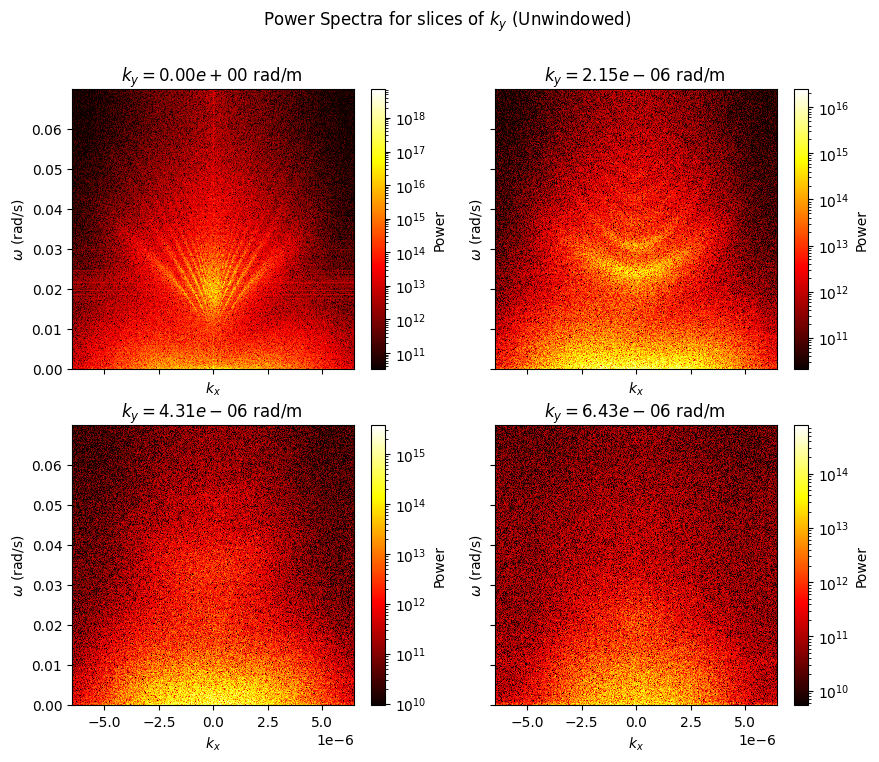

In [22]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
from google.colab import drive
from astropy.io import fits
import scipy.fft as sfft

#Define frequency axes
#Use fftshift to reorder the array to return nice plots with 0 frequency in the middle (idea from Claude)
omega = 2 * np.pi * sfft.rfftfreq(t.size, d=cadence) # rad/s
kx = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(x.size, d=convert_to_meters(1))) #rad/m
ky = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(y.size, d=convert_to_meters(1))) #rad/m

#Make multiple figures
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), sharex=True, sharey=True)

# For ky = 0, slice at ky index 0 (which is at the center index due to fftshift)
ky_index = [192, 256, 320, 383]

for i, ax in enumerate(axs.flat):
  raw = (ky_index[i] - 192) % 384    # same position in P's unshifted ky axis (for labeling)
  power = np.fft.fftshift(P[:, :, raw], axes=1) # Shape: (omega, kx)

  im = ax.pcolormesh(kx, omega, power, shading='auto', cmap='hot',
                              norm=colors.LogNorm(vmin=np.percentile(power, 5),
                                                  vmax=power.max()))
  fig.colorbar(im, label='Power')
  ax.set_ylabel(r'$\omega$ (rad/s)')
  ax.set_xlabel(r'$k_x$')
  ax.set_title(rf'$k_y={np.abs(ky[ky_index[i]]):.2e}$ rad/m ')


fig.suptitle(rf'Power Spectra for slices of $k_y$ (Unwindowed)')
plt.show()

Window the data, then take the FFT

(2304, 382, 382)


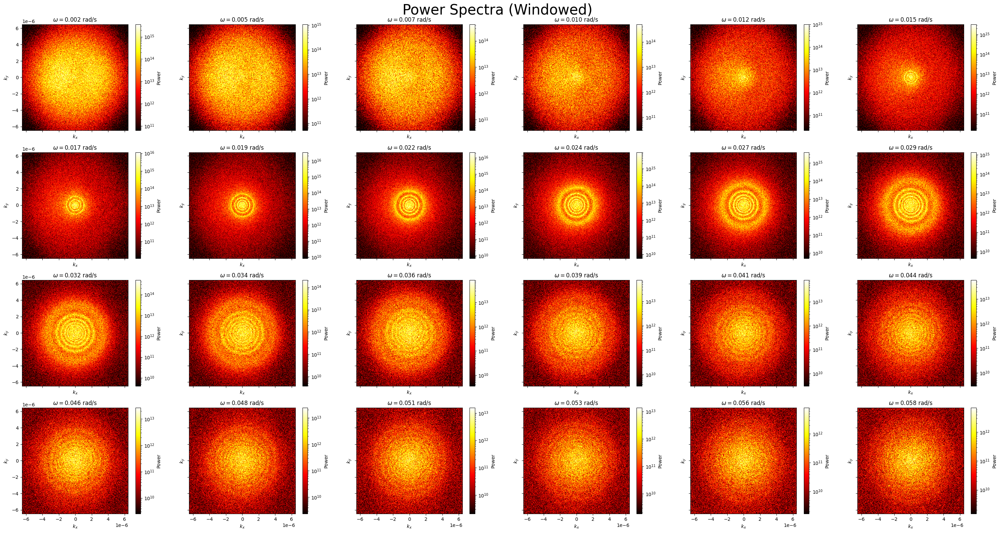

In [33]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
from google.colab import drive
from astropy.io import fits
import scipy.fft as sfft

def window(x, y, R):
  # Create a 2D grid of coordinates using meshgrid to calculate radial distance
  xv, yv = np.meshgrid(x, y, indexing='ij')
  r = np.sqrt(xv**2 + yv**2)
  # Apply the window function element-wise, using np.nan instead of 0 outside R
  return np.where(r < R, 1 - (r/R)**2, 0)

#Slice original data array using indexing (with help from Gemini + Claude)
# STEP 1: Compute the 2D window grid, center at 0
xc = x_coords - x_coords.mean()
yc = y_coords - y_coords.mean()
window_grid = window(xc, yc, xc.max()).astype(np.float32)

# STEP 2: Find spatial indices along each axis where the window is NOT nan
# We check along axis 0 (columns) and axis 1 (rows) to find the valid boundaries
nonzero_y, nonzero_x = np.where(window_grid!=0)
y_min, y_max = nonzero_y.min(), nonzero_y.max()
x_min, x_max = nonzero_x.min(), nonzero_x.max()

# STEP 3: Slice the coordinate arrays
x_coords_reduced = x_coords[x_min:x_max+1]
y_coords_reduced = y_coords[y_min:y_max+1]

# STEP 4: Slice the 3D dataset using the same spatial boundaries and apply the sliced window
windowed_data = data[:, x_min:x_max+1, y_min:y_max+1] * window_grid[y_min:y_max+1, x_min:x_max+1]
print(windowed_data.shape)

#Take FFT #Note--I'm using similar memory saving stragies as above via Claude (since it still crashes)
sub = data.astype(np.float32)
sub *= window_grid[None, :, :]                             # in place, no big temporary


#Define new x, y and t for windowed_data
t, x, y = sub.shape

# real FFT over time (axis 0), full FFT over x and y
F = sfft.rfftn(sub, axes=(1, 2, 0), workers=-1)

P = F.real**2 + F.imag**2              # power spectrum
del F, sub                               # free memory

#Define frequency axes
#Use fftshift to reorder the array to return nice plots with 0 frequency in the middle (idea from Claude)
omega = 2 * np.pi * sfft.rfftfreq(t, d=cadence) # rad/s
kx = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(x, d=convert_to_meters(1))) #rad/m
ky = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(y, d=convert_to_meters(1))) #rad/m


# Create a 5x8 grid of subplots
fig, axs = plt.subplots(nrows=4, ncols=6, sharex=True, sharey=True, figsize=(30, 16))

for i, ax in enumerate(axs.flat):
  #NOTE: again take transpose because rows = y, columns = x   (what pcolormesh expects)
  power = np.fft.fftshift(P[(i+1)*40, :, :]).T
  im = ax.pcolormesh(kx, ky, power, shading='auto', cmap='hot',
                          norm=colors.LogNorm(vmin=np.percentile(power, 5),
                                              vmax=power.max())) #idea for log color map was from Google AI overview
  fig.colorbar(im, label='Power')
  ax.set_ylabel(r'$k_y$')
  ax.set_xlabel(r'$k_x$')
  ax.set_title(rf'$\omega={omega[(i+1)*40]:.3f}$ rad/s ')
  ax.set_box_aspect(1)

fig.suptitle('Power Spectra (Windowed)', fontsize=30)
plt.tight_layout()
plt.show()


Showing the power as a function of $k_x$ and $\omega$ for a section with $k_y=0$ (Windowed)

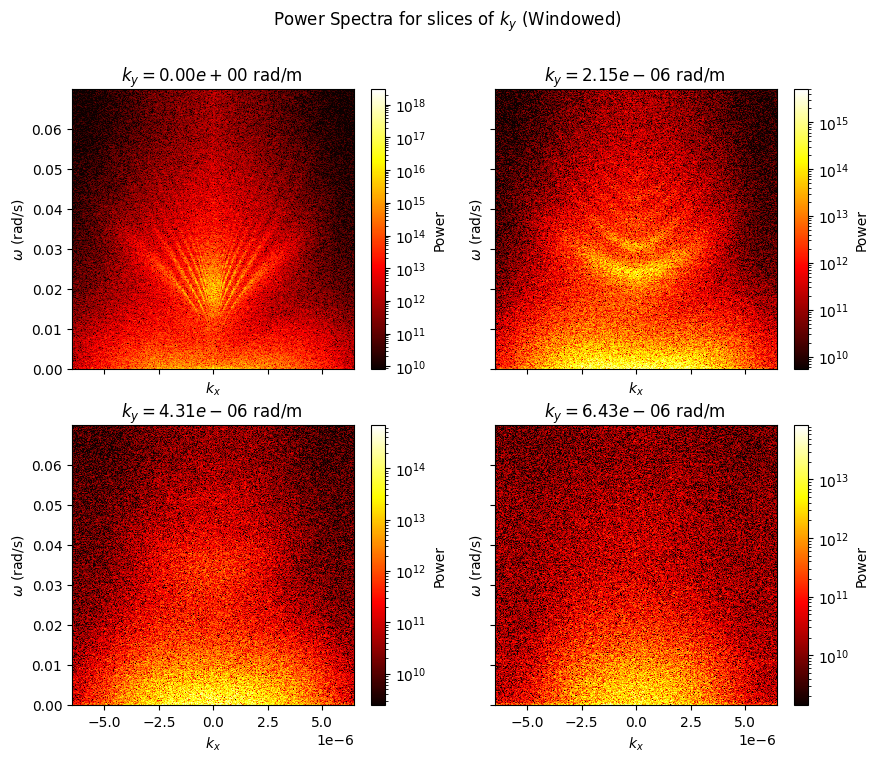

In [34]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
from google.colab import drive
from astropy.io import fits
import scipy.fft as sfft

#Define frequency axes
#Use fftshift to reorder the array to return nice plots with 0 frequency in the middle (idea from Claude)
omega = 2 * np.pi * sfft.rfftfreq(t, d=cadence) # rad/s
kx = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(x, d=convert_to_meters(1))) #rad/m
ky = 2 * np.pi * np.fft.fftshift(sfft.fftfreq(y, d=convert_to_meters(1))) #rad/m

#Make multiple figures
fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), sharex=True, sharey=True)

# For ky = 0, slice at ky index 0 (which is at the center index due to fftshift)
ky_index = [192, 256, 320, 383]

for i, ax in enumerate(axs.flat):
  raw = (ky_index[i] - 192) % 384    # same position in P's unshifted ky axis (for labeling)
  power = np.fft.fftshift(P[:, :, raw], axes=1) # Shape: (omega, kx)

  im = ax.pcolormesh(kx, omega, power, shading='auto', cmap='hot',
                              norm=colors.LogNorm(vmin=np.percentile(power, 5),
                                                  vmax=power.max()))
  fig.colorbar(im, label='Power')
  ax.set_ylabel(r'$\omega$ (rad/s)')
  ax.set_xlabel(r'$k_x$')
  ax.set_title(rf'$k_y={np.abs(ky[ky_index[i]]):.2e}$ rad/m ')


fig.suptitle(rf'Power Spectra for slices of $k_y$ (Windowed)')
plt.show()

##Problem 3

Plot the binned power for these wavenumbers as a function of temporal frequency (unwindowed)

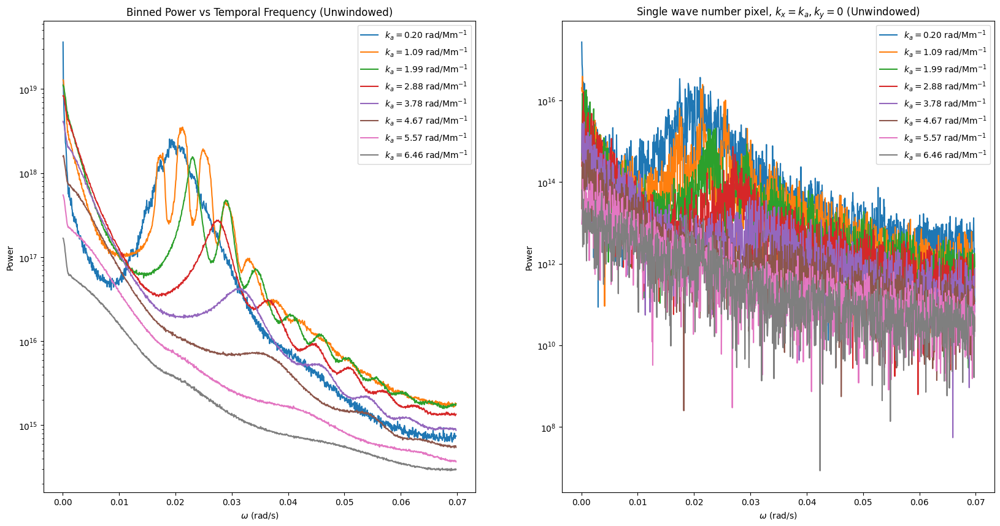

In [27]:
# |k| for every pixel, in the same order as P's (kx, ky) axes (using help from Cluade)
KX, KY = np.meshgrid(kx, ky, indexing='ij')     # indexed [kx, ky], like P[:, kx, ky]
k = np.sqrt(KX**2 + KY**2)                               # shape (384, 384)
converted_k = k * 1e6

# Note # 1: k is not low enough such that the binning index will be negative, so we choose 0.2 to be the lower bound
# Note # 2: Nyquist frequency should be the upper bound
k_nyq = np.abs(kx).max()  * 1e6
rep_wavenumbers = np.linspace(0.2, k_nyq, 8)

#Now bin data by adding up power within a small delta (we can define it as (max-min)/100)
delta = (converted_k.max() - converted_k.min()) / 100
binned_powers = []
kx_binned_powers = []

# Find the index where ky is closest to 0 (which is at index 192 since ky is fftshifted)
ky_zero_idx = 192
kx_raw = np.fft.ifftshift(kx)

#Logic in for loop was assisted by Google Colab's Gemini assistant
for ka in rep_wavenumbers:
  mask = np.abs(converted_k - ka) <= delta
  mask_raw = np.fft.ifftshift(mask)    # reorder to match unshifted P from previous cell
  binned_powers.append(P[:, mask_raw].sum(axis=1))

  # For single pixel (kx = ka, ky = 0), find the index of kx closest to ka (in converted units)
  kx_idx = np.argmin(np.abs(kx_raw * 1e6 - ka))
  kx_binned_powers.append(P[:, kx_idx, 0])

fig, axs = plt.subplots(1, 2, figsize=(20, 10))

#Make it a log plot
for i, ka in enumerate(rep_wavenumbers):
  axs[0].semilogy(omega[1:], binned_powers[i][1:], label=rf'$k_a={ka:.2f}$ rad/Mm$^{{-1}}$')
  axs[1].semilogy(omega[1:], kx_binned_powers[i][1:], label=rf'$k_a={ka:.2f}$ rad/Mm$^{{-1}}$')

axs[0].set_xlabel(r'$\omega$ (rad/s)')
axs[0].set_ylabel('Power')
axs[0].set_title('Binned Power vs Temporal Frequency (Unwindowed)')
axs[0].legend(loc='upper right')

axs[1].set_xlabel(r'$\omega$ (rad/s)')
axs[1].set_ylabel('Power')
axs[1].set_title('Single wave number pixel, $k_x = k_a, k_y = 0$ (Unwindowed)')
axs[1].legend(loc='upper right')

plt.show()

Plot the binned power for these wavenumbers as a function of temporal frequency (windowed)

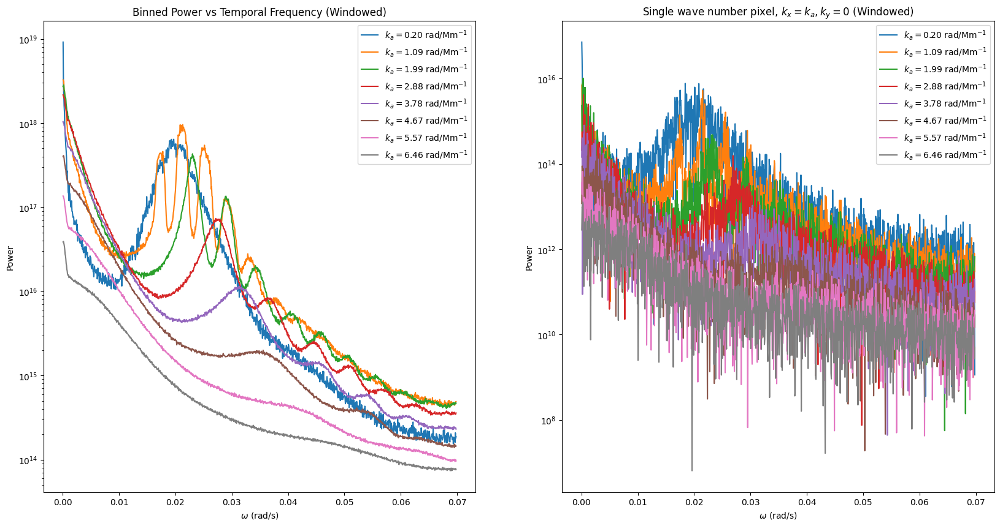

In [37]:
# |k| for every pixel, in the same order as P's (kx, ky) axes (using help from Cluade)
KX, KY = np.meshgrid(kx, ky, indexing='ij')     # indexed [kx, ky], like P[:, kx, ky]
k = np.sqrt(KX**2 + KY**2)                               # shape (192, 192)
converted_k = k * 1e6

# Note # 1: k is not low enough such that the binning index will be negative, so we choose 0.2 to be the lower bound
# Note # 2: Nyquist frequency should be the upper bound
k_nyq = np.abs(kx).max()  * 1e6
rep_wavenumbers = np.linspace(0.2, k_nyq, 8)

#Now bin data by adding up power within a small delta (we can define it as (max-min)/100)
delta = (converted_k.max() - converted_k.min()) / 100
binned_powers = []
kx_binned_powers = []

# Find the index where ky is closest to 0 (which is at index 192 since ky is fftshifted)
ky_zero_idx = 192
kx_raw = np.fft.ifftshift(kx)

#Logic in for loop was assisted by Google Colab's Gemini assistant
for ka in rep_wavenumbers:
  mask = np.abs(converted_k - ka) <= delta
  mask_raw = np.fft.ifftshift(mask)    # reorder to match unshifted P from previous cell
  binned_powers.append(P[:, mask_raw].sum(axis=1))

  # For single pixel (kx = ka, ky = 0), find the index of kx closest to ka (in converted units)
  kx_idx = np.argmin(np.abs(kx_raw * 1e6 - ka))
  kx_binned_powers.append(P[:, kx_idx, 0])

fig, axs = plt.subplots(1, 2, figsize=(20, 10))

#Make it a log plot
for i, ka in enumerate(rep_wavenumbers):
  axs[0].semilogy(omega[1:], binned_powers[i][1:], label=rf'$k_a={ka:.2f}$ rad/Mm$^{{-1}}$')
  axs[1].semilogy(omega[1:], kx_binned_powers[i][1:], label=rf'$k_a={ka:.2f}$ rad/Mm$^{{-1}}$')

axs[0].set_xlabel(r'$\omega$ (rad/s)')
axs[0].set_ylabel('Power')
axs[0].set_title('Binned Power vs Temporal Frequency (Windowed)')
axs[0].legend(loc='upper right')

axs[1].set_xlabel(r'$\omega$ (rad/s)')
axs[1].set_ylabel('Power')
axs[1].set_title('Single wave number pixel, $k_x = k_a, k_y = 0$ (Windowed)')
axs[1].legend(loc='upper right')

plt.show()

In [18]:
ix = np.argmin(np.abs(np.fft.ifftshift(kx) * 1e6 - ka))   # index in P's (unshifted) kx order
single = P[:, ix, 0]
print(np.fft.ifftshift(kx)[ix] * 1e6)                     # should print ka

6.428702214435477


$k$ vs $\omega$, using a colormap for power

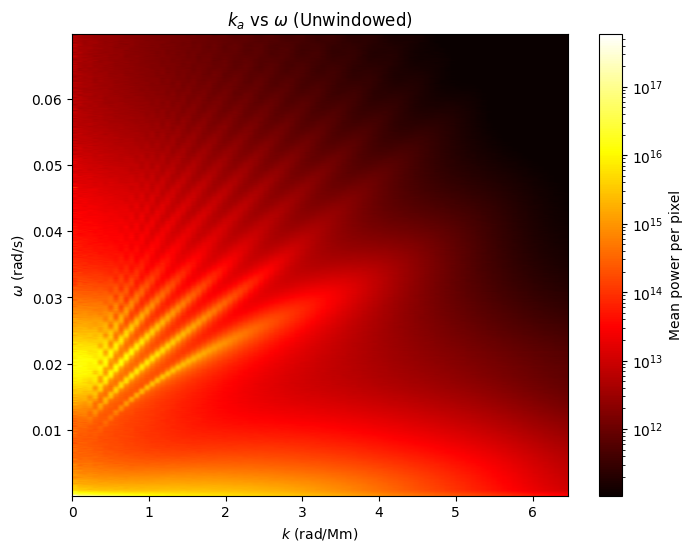

In [28]:
#This code was generated by Claude; I was just curious to see what would happen!

dk = np.abs(kx[1] - kx[0]) * 1e6                  # rad/Mm
k_nyq = np.abs(kx).max() * 1e6
dk_bin = 2 * dk                                   # ring width; dk gives more noise at low k

kmag_raw = np.fft.ifftshift(converted_k)          # |k| in P's (unshifted) order
kbin = np.floor(kmag_raw / dk_bin).astype(int).ravel()
nb = int(k_nyq / dk_bin)                          # only rings fully inside the Nyquist circle
idx = np.nonzero(kbin < nb)[0]
kw = kbin[idx]

Pflat = P.reshape(P.shape[0], -1)                 # view, no copy
Pk = np.empty((P.shape[0], nb))
for i in range(P.shape[0]):
    Pk[i] = np.bincount(kw, weights=Pflat[i][idx], minlength=nb)

counts = np.bincount(kw, minlength=nb)
Pk_mean = Pk / counts                             # mean power per pixel, so it doesn't grow with k

plt.figure(figsize=(8, 6))
plt.imshow(Pk_mean[1:], origin='lower', aspect='auto', cmap='hot',
           extent=[0, nb*dk_bin, omega[1], omega[-1]],
           norm=colors.LogNorm(vmin=np.percentile(Pk_mean[1:], 5), vmax=Pk_mean[1:].max()))
plt.colorbar(label='Mean power per pixel')
plt.xlabel(r'$k$ (rad/Mm)')
plt.ylabel(r'$\omega$ (rad/s)')
plt.title(r'$k_a$ vs $\omega$ (Unwindowed)')
plt.show()

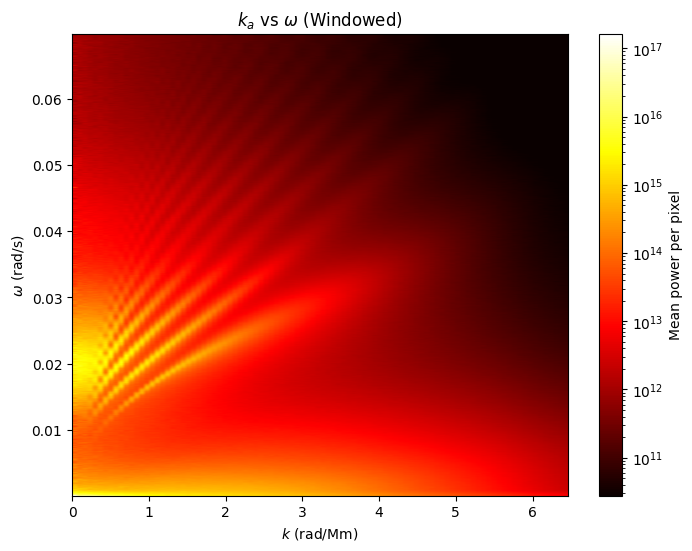

In [38]:
#This code was also generated by Claude; I was just curious to see what would happen!

dk = np.abs(kx[1] - kx[0]) * 1e6                  # rad/Mm
k_nyq = np.abs(kx).max() * 1e6
dk_bin = 2 * dk                                   # ring width; dk gives more noise at low k

kmag_raw = np.fft.ifftshift(converted_k)          # |k| in P's (unshifted) order
kbin = np.floor(kmag_raw / dk_bin).astype(int).ravel()
nb = int(k_nyq / dk_bin)                          # only rings fully inside the Nyquist circle
idx = np.nonzero(kbin < nb)[0]
kw = kbin[idx]

Pflat = P.reshape(P.shape[0], -1)                 # view, no copy
Pk = np.empty((P.shape[0], nb))
for i in range(P.shape[0]):
    Pk[i] = np.bincount(kw, weights=Pflat[i][idx], minlength=nb)

counts = np.bincount(kw, minlength=nb)
Pk_mean = Pk / counts                             # mean power per pixel, so it doesn't grow with k

plt.figure(figsize=(8, 6))
plt.imshow(Pk_mean[1:], origin='lower', aspect='auto', cmap='hot',
           extent=[0, nb*dk_bin, omega[1], omega[-1]],
           norm=colors.LogNorm(vmin=np.percentile(Pk_mean[1:], 5), vmax=Pk_mean[1:].max()))
plt.colorbar(label='Mean power per pixel')
plt.xlabel(r'$k$ (rad/Mm)')
plt.ylabel(r'$\omega$ (rad/s)')
plt.title(r'$k_a$ vs $\omega$ (Windowed)')
plt.show()